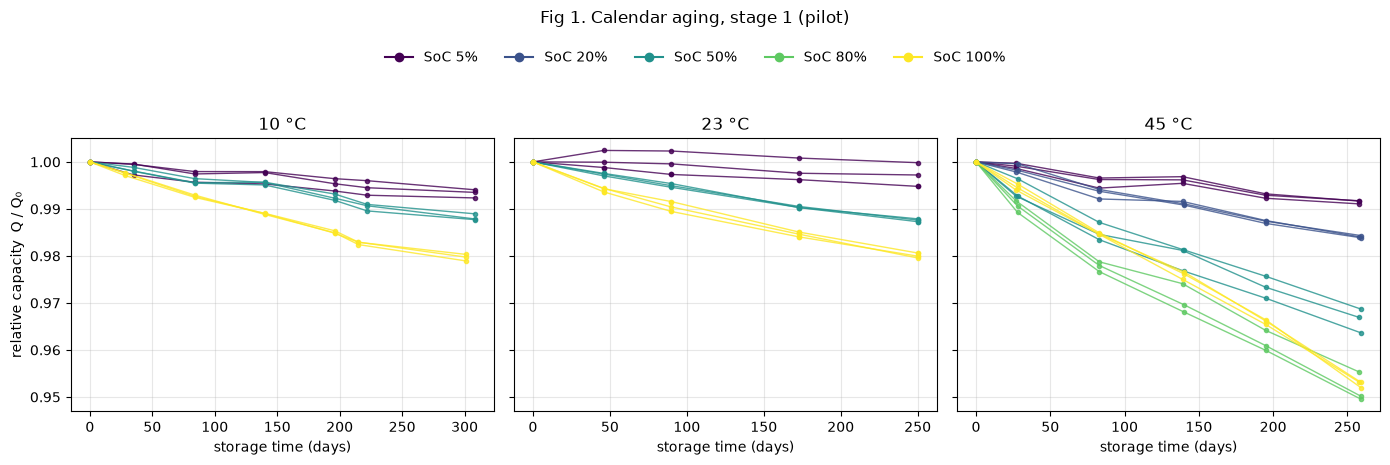

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# figure 1: calendar aging
cap = pd.read_parquet("../data/processed/capacity_rpt.parquet")            # the table you just built (loads in about a second)
d = cap[(cap["type"] == "k") & (cap["stage"] == 1)                        # calendar cells, stage 1 only
        & cap["kind"].isin(["CU", "exCU"])                                 # regular check-ups only (skip entry/end tests, which use a different protocol)
        & (cap["n_dis_rows"] > 0)].copy()                                  # drop the few tests with no capacity discharge
d = d.sort_values(["cell_id", "date"])
d["days"] = (d["date"] - d.groupby("cell_id")["date"].transform("min")).dt.days   # days since each cell's first check-up
d["Q_rel"] = d["Q_Ah"] / d.groupby("cell_id")["Q_Ah"].transform("first")   # capacity relative to that first check-up (1.0 = no fade)

temps = sorted(d["amb_temp_tp"].unique())                                  # 10, 23, 45 °C
socs = sorted(d["soc_max_tp"].unique())                                    # storage SoC levels
cmap = plt.get_cmap("viridis", len(socs))                                  # one color per SoC: dark = low, yellow = high

fig, axes = plt.subplots(1, len(temps), figsize=(14, 4), sharey=True)      # one panel per temperature, shared y-axis for comparison
for ax, T in zip(axes, temps):
    for cid, g in d[d["amb_temp_tp"] == T].groupby("cell_id"):             # one line per cell
        k = socs.index(g["soc_max_tp"].iloc[0])
        ax.plot(g["days"], g["Q_rel"], "-o", ms=3, lw=1, color=cmap(k), alpha=0.8)
    ax.set_title(f"{T:.0f} °C")
    ax.set_xlabel("storage time (days)")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("relative capacity  Q / Q₀")

handles = [plt.Line2D([], [], color=cmap(i), marker="o", label=f"SoC {s:.0%}") for i, s in enumerate(socs)]   # legend: one entry per SoC
fig.legend(handles=handles, loc="upper center", ncol=len(socs), bbox_to_anchor=(0.5, 1.08), frameon=False)
fig.suptitle("Fig 1. Calendar aging, stage 1 (pilot)", y=1.15)
plt.tight_layout()
plt.savefig("../figs/fig1_calendar_s1.png", dpi=200, bbox_inches="tight")
plt.show()

In [2]:
z = cap[(cap["type"] == "z") & cap["kind"].isin(["CU", "exCU"])]   # cycle cells, regular check-ups
print(z.groupby("cell_id").size().describe())                      # check-ups per cycle cell: min, typical, max
print(sorted(z.columns))                                           # see if any column already measures throughput (Ah or full cycles)

count    147.000000
mean      13.578231
std        4.006716
min        3.000000
25%       11.000000
50%       14.000000
75%       15.000000
max       22.000000
dtype: float64
['Q_Ah', 'R_1khz_0', 'U_0', 'amb_temp_tp', 'c_ch_tp', 'c_dch_tp', 'cell', 'cell_id', 'cu', 'date', 'days', 'dod_tp', 'file_name', 'kind', 'lab', 'm_0', 'n_dis_rows', 'resistance_meter', 'sampling', 'scale', 'soc_max_tp', 'stage', 'tp', 'type', 'volt_meter', 'zip']
